In [44]:
import sys
import torch

print(sys.executable)
print(torch.__version__)

C:\Users\Mystic\Desktop\ml-systems\.venv\Scripts\python.exe
2.15.0+cpu


In [45]:
import torch.nn as nn

torch.manual_seed(42)

X = torch.tensor([
    [1.0],
    [2.0],
    [3.0],
    [4.0],
    [5.0]
])

y = torch.tensor([
    [5.0],
    [8.0],
    [11.0],
    [14.0],
    [17.0]
])

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: torch.Size([5, 1])
y shape: torch.Size([5, 1])


In [46]:
model = nn.Linear(1,1)

print("Initial Weight:", model.weight.item())
print("Initial Bias:", model.bias.item())

predictions = model(X)
print("Predictions:")

print(predictions)


Initial Weight: 0.7645385265350342
Initial Bias: 0.8300079107284546
Predictions:
tensor([[1.5945],
        [2.3591],
        [3.1236],
        [3.8882],
        [4.6527]], grad_fn=<AddmmBackward0>)


In [47]:
loss_fn = nn.MSELoss()

predictions = model(X)
loss = loss_fn(predictions, y)

print("Predictions:", predictions.detach().squeeze())
print("Targets:", y.squeeze())
print("Initial MSE:", loss.item())

Predictions: tensor([1.5945, 2.3591, 3.1236, 3.8882, 4.6527])
Targets: tensor([ 5.,  8., 11., 14., 17.])
Initial MSE: 72.0318832397461


In [48]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

print("Model Parameters")
for name,parameter in model.named_parameters():
    print(name, parameter.data)

Model Parameters
weight tensor([[0.7645]])
bias tensor([0.8300])


In [49]:
losses = []

for epoch in range(2000):
    predictions = model(X)
    loss = loss_fn(predictions, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if epoch%400 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.6f}")

print("Learned Weight: " , model.weight.item())
print("Learned Bias: ", model.bias.item())

Epoch 0: Loss = 72.031883
Epoch 400: Loss = 0.003171
Epoch 800: Loss = 0.000211
Epoch 1200: Loss = 0.000014
Epoch 1600: Loss = 0.000001
Learned Weight:  3.0001626014709473
Learned Bias:  1.9994134902954102


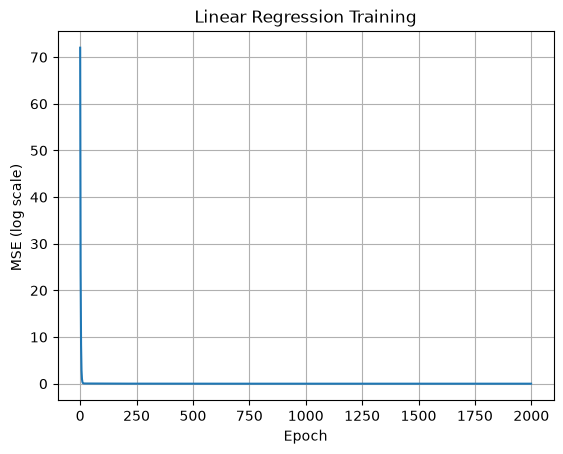

In [50]:
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE (log scale) ")
plt.title("Linear Regression Training")
plt.grid(True)
plt.show()

In [51]:
model.eval()

with torch.no_grad():
    test_input = torch.tensor([[6.0]])
    result = model(test_input)

print("Prediction for x=6:", result.item())

Prediction for x=6: 20.000389099121094


In [52]:
model.eval()

normal_output = model(torch.tensor([6.0]))



with torch.no_grad():
    no_grad_output = model(torch.tensor([6.0]))

print("Normal output:", normal_output.item())
print("Requires grad:", normal_output.requires_grad)
                           
print("No-grad output:", no_grad_output.item())
print("Requires grad:", no_grad_output.requires_grad)

Normal output: 20.000389099121094
Requires grad: True
No-grad output: 20.000389099121094
Requires grad: False


In [55]:
torch.manual_seed(42)

demo_model = nn.Linear(1, 1)
demo_loss_fn = nn.MSELoss()
demo_optimizer = torch.optim.SGD(
    demo_model.parameters(),
    lr=0.01
)

for epoch in range(3):
    predictions = demo_model(X)
    loss = demo_loss_fn(predictions, y)

    demo_optimizer.zero_grad()
    loss.backward()

    print(f"\nEpoch {epoch}")
    print("Weight before:", demo_model.weight.item())
    print("Bias before:", demo_model.bias.item())
    print("Loss:", loss.item())
    print("Weight gradient:", demo_model.weight.grad.item())
    print("Bias gradient:", demo_model.bias.grad.item())

    demo_optimizer.step()

    print("Weight after:", demo_model.weight.item())
    print("Bias after:", demo_model.bias.item())


Epoch 0
Weight before: 0.7645385265350342
Bias before: 0.8300079107284546
Loss: 72.0318832397461
Weight gradient: -56.200103759765625
Bias gradient: -15.752753257751465
Weight after: 1.3265395164489746
Bias after: 0.9875354766845703

Epoch 1
Weight before: 1.3265395164489746
Bias before: 0.9875354766845703
Loss: 41.99617004394531
Weight gradient: -42.89091873168945
Bias gradient: -12.065691947937012
Weight after: 1.7554486989974976
Bias after: 1.1081924438476562

Epoch 2
Weight before: 1.7554486989974976
Bias before: 1.1081924438476562
Loss: 24.49271011352539
Weight gradient: -32.73097229003906
Bias gradient: -9.250923156738281
Weight after: 2.0827584266662598
Bias after: 1.2007017135620117
